In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import warnings 

warnings.filterwarnings('ignore')

In [3]:
# Load datasets
train_df = pd.read_csv("fraudTrain.csv")
test_df = pd.read_csv("fraudTest.csv")

print("Training dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)

Training dataset shape: (1296675, 23)
Testing dataset shape: (555719, 23)


In [4]:
# Display all column names
print("Columns in the dataset:")
print(train_df.columns.tolist())

# Display first 5 rows
print("\nFirst 5 rows:")
display(train_df.head())

Columns in the dataset:
['Unnamed: 0', 'trans_date_trans_time', 'cc_num', 'merchant', 'category', 'amt', 'first', 'last', 'gender', 'street', 'city', 'state', 'zip', 'lat', 'long', 'city_pop', 'job', 'dob', 'trans_num', 'unix_time', 'merch_lat', 'merch_long', 'is_fraud']

First 5 rows:


,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,...,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,...,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,...,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,...,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,...,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [5]:
# Check data types 

print("Data Types:")
print(train_df.dtypes)

Data Types:
Unnamed: 0                 int64
trans_date_trans_time        str
cc_num                     int64
merchant                     str
category                     str
amt                      float64
first                        str
last                         str
gender                       str
street                       str
city                         str
state                        str
zip                        int64
lat                      float64
long                     float64
city_pop                   int64
job                          str
dob                          str
trans_num                    str
unix_time                  int64
merch_lat                float64
merch_long               float64
is_fraud                   int64
dtype: object


In [6]:
print("\nMissing Values:")
print(train_df.isnull().sum())


Missing Values:
Unnamed: 0               0
trans_date_trans_time    0
cc_num                   0
merchant                 0
category                 0
amt                      0
first                    0
last                     0
gender                   0
street                   0
city                     0
state                    0
zip                      0
lat                      0
long                     0
city_pop                 0
job                      0
dob                      0
trans_num                0
unix_time                0
merch_lat                0
merch_long               0
is_fraud                 0
dtype: int64


In [7]:
# Check the distribution of the target variable

print("Fraud Distribution:")
print(train_df["is_fraud"].value_counts())

print("\nFraud Percentage:")
print(train_df["is_fraud"].value_counts(normalize=True) * 100)

Fraud Distribution:
is_fraud
0    1289169
1       7506
Name: count, dtype: int64

Fraud Percentage:
is_fraud
0    99.421135
1     0.578865
Name: proportion, dtype: float64


In [8]:
# Check for duplicate rows

print("Duplicate rows in training data:", train_df.duplicated().sum())

print("Duplicate rows in testing data:", test_df.duplicated().sum())


Duplicate rows in training data: 0
Duplicate rows in testing data: 0


In [9]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1296675 entries, 0 to 1296674
Data columns (total 23 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   Unnamed: 0             1296675 non-null  int64  
 1   trans_date_trans_time  1296675 non-null  str    
 2   cc_num                 1296675 non-null  int64  
 3   merchant               1296675 non-null  str    
 4   category               1296675 non-null  str    
 5   amt                    1296675 non-null  float64
 6   first                  1296675 non-null  str    
 7   last                   1296675 non-null  str    
 8   gender                 1296675 non-null  str    
 9   street                 1296675 non-null  str    
 10  city                   1296675 non-null  str    
 11  state                  1296675 non-null  str    
 12  zip                    1296675 non-null  int64  
 13  lat                    1296675 non-null  float64
 14  long                   129667

In [10]:
train_df.describe()

,Unnamed: 0,cc_num,amt,zip,lat,long,city_pop,unix_time,merch_lat,merch_long,is_fraud
count,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06
mean,6.483370e+05,4.171920e+17,7.035104e+01,4.880067e+04,3.853762e+01,-9.022634e+01,8.882444e+04,1.349244e+09,3.853734e+01,-9.022646e+01,5.788652e-03
std,3.743180e+05,1.308806e+18,1.603160e+02,2.689322e+04,5.075808e+00,1.375908e+01,3.019564e+05,1.284128e+07,5.109788e+00,1.377109e+01,7.586269e-02
min,0.000000e+00,6.041621e+10,1.000000e+00,1.257000e+03,2.002710e+01,-1.656723e+02,2.300000e+01,1.325376e+09,1.902779e+01,-1.666712e+02,0.000000e+00
25%,3.241685e+05,1.800429e+14,9.650000e+00,2.623700e+04,3.462050e+01,-9.679800e+01,7.430000e+02,1.338751e+09,3.473357e+01,-9.689728e+01,0.000000e+00
50%,6.483370e+05,3.521417e+15,4.752000e+01,4.817400e+04,3.935430e+01,-8.747690e+01,2.456000e+03,1.349250e+09,3.936568e+01,-8.743839e+01,0.000000e+00
75%,9.725055e+05,4.642255e+15,8.314000e+01,7.204200e+04,4.194040e+01,-8.015800e+01,2.032800e+04,1.359385e+09,4.195716e+01,-8.023680e+01,0.000000e+00
max,1.296674e+06,4.992346e+18,2.894890e+04,9.978300e+04,6.669330e+01,-6.795030e+01,2.906700e+06,1.371817e+09,6.751027e+01,-6.695090e+01,1.000000e+00


In [11]:
# Number of unique values in each column

unique_counts = train_df.nunique().sort_values()

print(unique_counts)

gender                         2
is_fraud                       2
category                      14
state                         51
first                        352
last                         481
job                          494
merchant                     693
city_pop                     879
city                         894
lat                          968
dob                          968
long                         969
zip                          970
street                       983
cc_num                       983
amt                        52928
merch_lat                1247805
trans_date_trans_time    1274791
unix_time                1274823
merch_long               1275745
Unnamed: 0               1296675
trans_num                1296675
dtype: int64


In [12]:
# Display categorical/text columns

categorical_columns = train_df.select_dtypes(include=["object"]).columns

print("Categorical columns:")
print(categorical_columns.tolist())

Categorical columns:
['trans_date_trans_time', 'merchant', 'category', 'first', 'last', 'gender', 'street', 'city', 'state', 'job', 'dob', 'trans_num']


In [13]:
# Display numerical columns

numerical_columns = train_df.select_dtypes(include=["int64", "float64"]).columns

print("Numerical columns:")
print(numerical_columns.tolist())

Numerical columns:
['Unnamed: 0', 'cc_num', 'amt', 'zip', 'lat', 'long', 'city_pop', 'unix_time', 'merch_lat', 'merch_long', 'is_fraud']


In [14]:
# Compare fraud distribution in training and testing datasets

print("Training dataset:")
print(train_df["is_fraud"].value_counts(normalize=True) * 100)

print("\nTesting dataset:")
print(test_df["is_fraud"].value_counts(normalize=True) * 100)

Training dataset:
is_fraud
0    99.421135
1     0.578865
Name: proportion, dtype: float64

Testing dataset:
is_fraud
0    99.614014
1     0.385986
Name: proportion, dtype: float64


# Exploratory Data Analysis

In [15]:
# Compare transaction amounts for legitimate and fraudulent transactions

print("Legitimate transactions:")
print(train_df[train_df["is_fraud"] == 0]["amt"].describe())

print("\nFraudulent transactions:")
print(train_df[train_df["is_fraud"] == 1]["amt"].describe())

Legitimate transactions:
count    1.289169e+06
mean     6.766711e+01
std      1.540080e+02
min      1.000000e+00
25%      9.610000e+00
50%      4.728000e+01
75%      8.254000e+01
max      2.894890e+04
Name: amt, dtype: float64

Fraudulent transactions:
count    7506.000000
mean      531.320092
std       390.560070
min         1.060000
25%       245.662500
50%       396.505000
75%       900.875000
max      1376.040000
Name: amt, dtype: float64


In [16]:
# Fraud count by transaction category

category_fraud = pd.crosstab(
    train_df["category"],
    train_df["is_fraud"]
)

print(category_fraud)

is_fraud             0     1
category                    
entertainment    93781   233
food_dining      91310   151
gas_transport   131041   618
grocery_net      45318   134
grocery_pos     121895  1743
health_fitness   85746   133
home            122917   198
kids_pets       112796   239
misc_net         62372   915
misc_pos         79405   250
personal_care    90538   220
shopping_net     95830  1713
shopping_pos    115829   843
travel           40391   116


In [17]:
# Fraud percentage within each transaction category

category_fraud_rate = (
    train_df.groupby("category")["is_fraud"]
    .mean()
    .sort_values(ascending=False) * 100
)

print(category_fraud_rate)

category
shopping_net      1.756149
misc_net          1.445795
grocery_pos       1.409761
shopping_pos      0.722538
gas_transport     0.469394
misc_pos          0.313853
grocery_net       0.294817
travel            0.286370
entertainment     0.247835
personal_care     0.242403
kids_pets         0.211439
food_dining       0.165098
home              0.160825
health_fitness    0.154869
Name: is_fraud, dtype: float64


In [18]:
# Check the transaction date range

train_df["trans_date_trans_time"] = pd.to_datetime(
    train_df["trans_date_trans_time"]
)

test_df["trans_date_trans_time"] = pd.to_datetime(
    test_df["trans_date_trans_time"]
)

print("Training data:")
print("Start:", train_df["trans_date_trans_time"].min())
print("End:", train_df["trans_date_trans_time"].max())

print("\nTesting data:")
print("Start:", test_df["trans_date_trans_time"].min())
print("End:", test_df["trans_date_trans_time"].max())

Training data:
Start: 2019-01-01 00:00:18
End: 2020-06-21 12:13:37

Testing data:
Start: 2020-06-21 12:14:25
End: 2020-12-31 23:59:34


In [19]:
# Fraud rate by gender

gender_fraud_rate = (
    train_df.groupby("gender")["is_fraud"]
    .mean()
    .sort_values(ascending=False) * 100
)

print(gender_fraud_rate)

gender
M    0.642625
F    0.526158
Name: is_fraud, dtype: float64


In [20]:
# Extract transaction hour

train_df["transaction_hour"] = train_df["trans_date_trans_time"].dt.hour

fraud_by_hour = (
    train_df.groupby("transaction_hour")["is_fraud"]
    .mean()
    .sort_values(ascending=False) * 100
)

print(fraud_by_hour)

transaction_hour
22    2.882864
23    2.837387
1     1.534909
0     1.494047
2     1.465210
3     1.423929
5     0.142278
7     0.132692
14    0.132542
19    0.123649
18    0.122633
13    0.122485
15    0.120812
17    0.119175
16    0.115632
8     0.115281
21    0.112920
9     0.111414
4     0.109882
12    0.102671
11    0.099805
20    0.095241
10    0.094628
6     0.094563
Name: is_fraud, dtype: float64


In [21]:
# Create copies so the original datasets remain unchanged

train = train_df.copy()
test = test_df.copy()

print("Training shape:", train.shape)
print("Testing shape:", test.shape)

Training shape: (1296675, 24)
Testing shape: (555719, 23)


In [22]:
# Extract useful features from transaction timestamp

for df in [train, test]:
    df["transaction_hour"] = df["trans_date_trans_time"].dt.hour
    df["transaction_day"] = df["trans_date_trans_time"].dt.day
    df["transaction_month"] = df["trans_date_trans_time"].dt.month
    df["transaction_dayofweek"] = df["trans_date_trans_time"].dt.dayofweek

print(train[[
    "trans_date_trans_time",
    "transaction_hour",
    "transaction_day",
    "transaction_month",
    "transaction_dayofweek"
]].head())

  trans_date_trans_time  transaction_hour  transaction_day  transaction_month  \
0   2019-01-01 00:00:18                 0                1                  1   
1   2019-01-01 00:00:44                 0                1                  1   
2   2019-01-01 00:00:51                 0                1                  1   
3   2019-01-01 00:01:16                 0                1                  1   
4   2019-01-01 00:03:06                 0                1                  1   

   transaction_dayofweek  
0                      1  
1                      1  
2                      1  
3                      1  
4                      1  


In [23]:
# Convert date of birth to datetime

train["dob"] = pd.to_datetime(train["dob"])
test["dob"] = pd.to_datetime(test["dob"])

# Calculate approximate age at transaction time

train["age"] = (
    (train["trans_date_trans_time"] - train["dob"]).dt.days / 365.25
).astype(int)

test["age"] = (
    (test["trans_date_trans_time"] - test["dob"]).dt.days / 365.25
).astype(int)

print(train["age"].describe())

count    1.296675e+06
mean     4.549541e+01
std      1.739698e+01
min      1.300000e+01
25%      3.200000e+01
50%      4.300000e+01
75%      5.700000e+01
max      9.500000e+01
Name: age, dtype: float64


In [24]:
# Calculate approximate geographic distance

def calculate_distance(lat1, lon1, lat2, lon2):
    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )

    return 6371 * 2 * np.arcsin(np.sqrt(a))


train["distance_km"] = calculate_distance(
    train["lat"],
    train["long"],
    train["merch_lat"],
    train["merch_long"]
)

test["distance_km"] = calculate_distance(
    test["lat"],
    test["long"],
    test["merch_lat"],
    test["merch_long"]
)

print(train["distance_km"].describe())

count    1.296675e+06
mean     7.611465e+01
std      2.911693e+01
min      2.225452e-02
25%      5.533491e+01
50%      7.823175e+01
75%      9.850327e+01
max      1.521172e+02
Name: distance_km, dtype: float64


In [25]:
# Select features for the machine learning model

features = [
    "amt",
    "lat",
    "long",
    "city_pop",
    "merch_lat",
    "merch_long",
    "transaction_hour",
    "transaction_day",
    "transaction_month",
    "transaction_dayofweek",
    "age",
    "distance_km",
    "gender",
    "category",
    "state"
]

X_train = train[features].copy()
X_test = test[features].copy()

y_train = train["is_fraud"]
y_test = test["is_fraud"]

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("Number of features:", len(features))

X_train shape: (1296675, 15)
X_test shape: (555719, 15)
Number of features: 15


In [26]:
# Inspect the final feature set

print("Features used:")
print(X_train.columns.tolist())

print("\nFirst 5 rows:")
display(X_train.head())

Features used:
['amt', 'lat', 'long', 'city_pop', 'merch_lat', 'merch_long', 'transaction_hour', 'transaction_day', 'transaction_month', 'transaction_dayofweek', 'age', 'distance_km', 'gender', 'category', 'state']

First 5 rows:


,amt,lat,long,city_pop,merch_lat,merch_long,transaction_hour,transaction_day,transaction_month,transaction_dayofweek,age,distance_km,gender,category,state
0,4.97,36.0788,-81.1781,3495,36.011293,-82.048315,0,1,1,1,30,78.597568,F,misc_net,NC
1,107.23,48.8878,-118.2105,149,49.159047,-118.186462,0,1,1,1,40,30.212176,F,grocery_pos,WA
2,220.11,42.1808,-112.2620,4154,43.150704,-112.154481,0,1,1,1,56,108.206083,M,entertainment,ID
3,45.00,46.2306,-112.1138,1939,47.034331,-112.561071,0,1,1,1,51,95.673231,M,gas_transport,MT
4,41.96,38.4207,-79.4629,99,38.674999,-78.632459,0,1,1,1,32,77.556744,M,misc_pos,VA


In [27]:
# Separate categorical and numerical features

categorical_features = [
    "gender",
    "category",
    "state"
]

numerical_features = [
    "amt",
    "lat",
    "long",
    "city_pop",
    "merch_lat",
    "merch_long",
    "transaction_hour",
    "transaction_day",
    "transaction_month",
    "transaction_dayofweek",
    "age",
    "distance_km"
]

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

Categorical features:
['gender', 'category', 'state']

Numerical features:
['amt', 'lat', 'long', 'city_pop', 'merch_lat', 'merch_long', 'transaction_hour', 'transaction_day', 'transaction_month', 'transaction_dayofweek', 'age', 'distance_km']


In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Preprocessing pipeline

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            ),
            categorical_features
        )
    ]
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [29]:
# Fit the preprocessor using only training data

X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data using the same preprocessor
X_test_processed = preprocessor.transform(X_test)

print("Training processed shape:", X_train_processed.shape)
print("Testing processed shape:", X_test_processed.shape)

Training processed shape: (1296675, 79)
Testing processed shape: (555719, 79)


In [30]:
# Check the type and shape of processed data

print("Processed data type:", type(X_train_processed))
print("Training rows:", X_train_processed.shape[0])
print("Training features:", X_train_processed.shape[1])

Processed data type: <class 'scipy.sparse._csr.csr_matrix'>
Training rows: 1296675
Training features: 79


In [31]:
# Get feature names after preprocessing

feature_names = preprocessor.get_feature_names_out()

print("Total features after encoding:", len(feature_names))

print("\nFirst 30 encoded features:")
print(feature_names[:30])

Total features after encoding: 79

First 30 encoded features:
['num__amt' 'num__lat' 'num__long' 'num__city_pop' 'num__merch_lat'
 'num__merch_long' 'num__transaction_hour' 'num__transaction_day'
 'num__transaction_month' 'num__transaction_dayofweek' 'num__age'
 'num__distance_km' 'cat__gender_F' 'cat__gender_M'
 'cat__category_entertainment' 'cat__category_food_dining'
 'cat__category_gas_transport' 'cat__category_grocery_net'
 'cat__category_grocery_pos' 'cat__category_health_fitness'
 'cat__category_home' 'cat__category_kids_pets' 'cat__category_misc_net'
 'cat__category_misc_pos' 'cat__category_personal_care'
 'cat__category_shopping_net' 'cat__category_shopping_pos'
 'cat__category_travel' 'cat__state_AK' 'cat__state_AL']


In [32]:
# Final check of target variable

print("Training target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training target distribution:
is_fraud
0    1289169
1       7506
Name: count, dtype: int64

Testing target distribution:
is_fraud
0    553574
1      2145
Name: count, dtype: int64


In [33]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.array([0, 1])

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weight_dict = dict(zip(classes, class_weights))

print("Class weights:")
print(class_weight_dict)

Class weights:
{np.int64(0): np.float64(0.5029111776656126), np.int64(1): np.float64(86.37589928057554)}


In [34]:
# Calculate the ratio between legitimate and fraud transactions

legitimate_count = (y_train == 0).sum()
fraud_count = (y_train == 1).sum()

print("Legitimate transactions:", legitimate_count)
print("Fraudulent transactions:", fraud_count)
print("Imbalance ratio:", legitimate_count / fraud_count)

Legitimate transactions: 1289169
Fraudulent transactions: 7506
Imbalance ratio: 171.75179856115108


In [35]:
# Check the processed feature matrix

print("Training matrix shape:", X_train_processed.shape)
print("Testing matrix shape:", X_test_processed.shape)

print("Training matrix type:", type(X_train_processed))

Training matrix shape: (1296675, 79)
Testing matrix shape: (555719, 79)
Training matrix type: <class 'scipy.sparse._csr.csr_matrix'>


In [36]:
from sklearn.model_selection import train_test_split

X_train_model, X_val, y_train_model, y_val = train_test_split(
    X_train_processed,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training data:", X_train_model.shape)
print("Validation data:", X_val.shape)

print("\nValidation target distribution:")
print(y_val.value_counts())

Training data: (1037340, 79)
Validation data: (259335, 79)

Validation target distribution:
is_fraud
0    257834
1      1501
Name: count, dtype: int64


In [37]:
print("Training fraud percentage:")
print(y_train_model.mean() * 100)

print("\nValidation fraud percentage:")
print(y_val.mean() * 100)

print("\nOriginal training fraud percentage:")
print(y_train.mean() * 100)

Training fraud percentage:
0.578884454470087

Validation fraud percentage:
0.5787880540613491

Original training fraud percentage:
0.5788651743883394


# TRAIN LOGISTIC REGRESSION

In [38]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Imports successful!")

Imports successful!


In [39]:
# Train baseline Logistic Regression model

logistic_model = LogisticRegression(
    class_weight="balanced",
    max_iter=100,
    solver="saga",
    random_state=42
)

print("Training Logistic Regression...")
logistic_model.fit(X_train_model, y_train_model)

print("Logistic Regression training completed!")

Training Logistic Regression...
Logistic Regression training completed!


In [40]:
# Make predictions on validation data

y_val_pred = logistic_model.predict(X_val)
y_val_proba = logistic_model.predict_proba(X_val)[:, 1]

print("Predictions completed!")

Predictions completed!


In [41]:
# Evaluate Logistic Regression

print("Classification Report:")
print(classification_report(
    y_val,
    y_val_pred,
    target_names=["Legitimate", "Fraud"]
))

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      0.88      0.94    257834
       Fraud       0.04      0.76      0.07      1501

    accuracy                           0.88    259335
   macro avg       0.52      0.82      0.50    259335
weighted avg       0.99      0.88      0.93    259335



In [42]:
# Confusion Matrix

cm = confusion_matrix(y_val, y_val_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[227504  30330]
 [   360   1141]]


In [43]:
# Calculate important fraud-detection metrics

accuracy = accuracy_score(y_val, y_val_pred)
precision = precision_score(y_val, y_val_pred)
recall = recall_score(y_val, y_val_pred)
f1 = f1_score(y_val, y_val_pred)
roc_auc = roc_auc_score(y_val, y_val_proba)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

Accuracy : 0.8817
Precision: 0.0363
Recall   : 0.7602
F1-Score : 0.0692
ROC-AUC  : 0.9149


In [44]:
# Store Logistic Regression results for later model comparison

results = {
    "Logistic Regression": {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": roc_auc
    }
}

print(results)

{'Logistic Regression': {'Accuracy': 0.8816588582335589, 'Precision': 0.036255600394013536, 'Recall': 0.760159893404397, 'F1-Score': 0.06921023899065874, 'ROC-AUC': 0.9148953457739417}}


In [45]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]

threshold_results = []

for threshold in thresholds:
    predictions = (y_val_proba >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1-Score": f1_score(y_val, predictions, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df)

,Threshold,Precision,Recall,F1-Score
0,0.1,0.008587,0.998668,0.017027
1,0.2,0.011834,0.968021,0.023382
2,0.3,0.016417,0.877415,0.032231
3,0.4,0.022922,0.800799,0.044569
4,0.5,0.036256,0.760160,0.069210
5,0.6,0.073930,0.745503,0.134519
6,0.7,0.165228,0.726849,0.269250
7,0.8,0.237252,0.660227,0.349067
8,0.9,0.241239,0.513658,0.328295


In [46]:
# Find the threshold with the highest F1-score

best_threshold_row = threshold_df.loc[
    threshold_df["F1-Score"].idxmax()
]

print("Best threshold based on F1-Score:")
print(best_threshold_row)

Best threshold based on F1-Score:
Threshold    0.800000
Precision    0.237252
Recall       0.660227
F1-Score     0.349067
Name: 7, dtype: float64


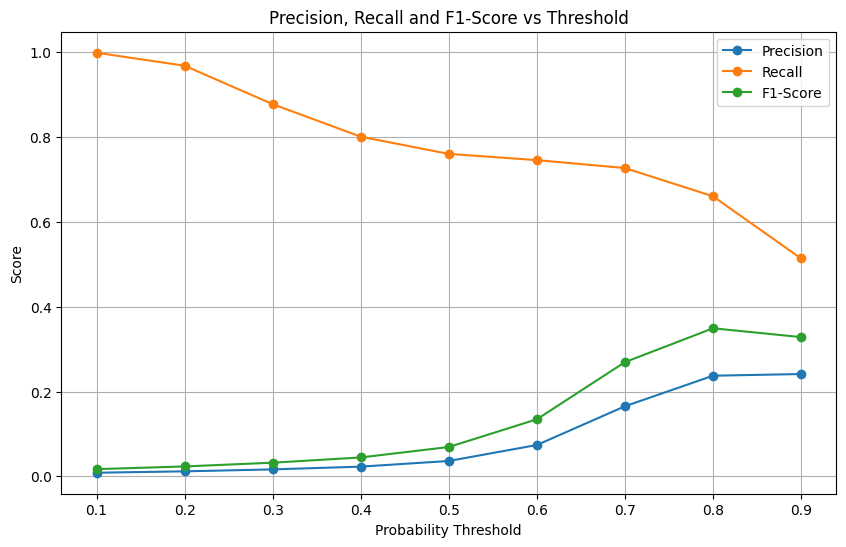

In [47]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1-Score"],
    marker="o",
    label="F1-Score"
)

plt.xlabel("Probability Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall and F1-Score vs Threshold")
plt.legend()
plt.grid(True)

plt.show()

In [48]:
# Evaluate Logistic Regression using the best threshold

best_threshold = best_threshold_row["Threshold"]

y_val_best_pred = (
    y_val_proba >= best_threshold
).astype(int)

print("Selected threshold:", best_threshold)

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        y_val_best_pred,
        target_names=["Legitimate", "Fraud"]
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_best_pred))

Selected threshold: 0.8

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      0.99      0.99    257834
       Fraud       0.24      0.66      0.35      1501

    accuracy                           0.99    259335
   macro avg       0.62      0.82      0.67    259335
weighted avg       0.99      0.99      0.99    259335


Confusion Matrix:
[[254648   3186]
 [   510    991]]


# RANDOM FOREST

In [49]:
from sklearn.ensemble import RandomForestClassifier

print("Random Forest imported successfully!")

Random Forest imported successfully!


In [50]:
# Train Random Forest

random_forest_model = RandomForestClassifier(
    n_estimators=50,
    max_depth=15,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

print("Training Random Forest...")
random_forest_model.fit(X_train_model, y_train_model)

print("Random Forest training completed!")

Training Random Forest...
Random Forest training completed!


In [51]:
# Make Random Forest predictions

rf_val_pred = random_forest_model.predict(X_val)
rf_val_proba = random_forest_model.predict_proba(X_val)[:, 1]

print("Random Forest predictions completed!")

Random Forest predictions completed!


In [52]:
# Random Forest classification report

print("Random Forest Classification Report:")

print(
    classification_report(
        y_val,
        rf_val_pred,
        target_names=["Legitimate", "Fraud"]
    )
)

Random Forest Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      0.99      1.00    257834
       Fraud       0.46      0.89      0.61      1501

    accuracy                           0.99    259335
   macro avg       0.73      0.94      0.80    259335
weighted avg       1.00      0.99      0.99    259335



In [53]:
# Random Forest confusion matrix

rf_cm = confusion_matrix(y_val, rf_val_pred)

print("Random Forest Confusion Matrix:")
print(rf_cm)

Random Forest Confusion Matrix:
[[256269   1565]
 [   161   1340]]


In [54]:
# Random Forest evaluation metrics

rf_accuracy = accuracy_score(y_val, rf_val_pred)
rf_precision = precision_score(y_val, rf_val_pred, zero_division=0)
rf_recall = recall_score(y_val, rf_val_pred, zero_division=0)
rf_f1 = f1_score(y_val, rf_val_pred, zero_division=0)
rf_roc_auc = roc_auc_score(y_val, rf_val_proba)

print(f"Accuracy : {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall   : {rf_recall:.4f}")
print(f"F1-Score : {rf_f1:.4f}")
print(f"ROC-AUC  : {rf_roc_auc:.4f}")

Accuracy : 0.9933
Precision: 0.4613
Recall   : 0.8927
F1-Score : 0.6083
ROC-AUC  : 0.9929


In [55]:
# Add Random Forest results

results["Random Forest"] = {
    "Accuracy": rf_accuracy,
    "Precision": rf_precision,
    "Recall": rf_recall,
    "F1-Score": rf_f1,
    "ROC-AUC": rf_roc_auc
}

results_df = pd.DataFrame(results).T

display(results_df)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.881659,0.036256,0.760160,0.069210,0.914895
Random Forest,0.993345,0.461274,0.892738,0.608261,0.992882


In [56]:
# Check Random Forest performance at different thresholds

rf_threshold_results = []

for threshold in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    
    rf_threshold_pred = (rf_val_proba >= threshold).astype(int)
    
    precision = precision_score(
        y_val, rf_threshold_pred, zero_division=0
    )
    
    recall = recall_score(
        y_val, rf_threshold_pred, zero_division=0
    )
    
    f1 = f1_score(
        y_val, rf_threshold_pred, zero_division=0
    )
    
    rf_threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

rf_threshold_df = pd.DataFrame(rf_threshold_results)

display(rf_threshold_df)

,Threshold,Precision,Recall,F1-Score
0,0.1,0.015899,0.996003,0.031298
1,0.2,0.050991,0.982012,0.096948
2,0.3,0.142128,0.965356,0.247777
3,0.4,0.279324,0.936043,0.430256
4,0.5,0.461274,0.892738,0.608261
5,0.6,0.626113,0.843438,0.718706
6,0.7,0.787838,0.776815,0.782288
7,0.8,0.939106,0.657562,0.773511
8,0.9,0.989870,0.455696,0.624088


In [57]:
# Select the best Random Forest threshold based on F1-Score

best_rf_threshold_row = rf_threshold_df.loc[
    rf_threshold_df["F1-Score"].idxmax()
]

best_rf_threshold = best_rf_threshold_row["Threshold"]

print("Best Random Forest threshold:")
print(best_rf_threshold_row)

print("\nSelected threshold:", best_rf_threshold)

Best Random Forest threshold:
Threshold    0.700000
Precision    0.787838
Recall       0.776815
F1-Score     0.782288
Name: 6, dtype: float64

Selected threshold: 0.7


In [58]:
# Generate predictions using the selected threshold

y_val_rf_best_pred = (
    rf_val_proba >= best_rf_threshold
).astype(int)

print("Predictions generated successfully!")
print("Threshold:", best_rf_threshold)

Predictions generated successfully!
Threshold: 0.7


In [59]:
# Calculate final Random Forest metrics

rf_final_accuracy = accuracy_score(y_val, y_val_rf_best_pred)
rf_final_precision = precision_score(
    y_val, y_val_rf_best_pred, zero_division=0
)
rf_final_recall = recall_score(
    y_val, y_val_rf_best_pred, zero_division=0
)
rf_final_f1 = f1_score(
    y_val, y_val_rf_best_pred, zero_division=0
)

print(f"Accuracy  : {rf_final_accuracy:.4f}")
print(f"Precision : {rf_final_precision:.4f}")
print(f"Recall    : {rf_final_recall:.4f}")
print(f"F1-Score  : {rf_final_f1:.4f}")

Accuracy  : 0.9975
Precision : 0.7878
Recall    : 0.7768
F1-Score  : 0.7823


In [60]:
# Detailed classification report

print("Final Random Forest Classification Report:\n")

print(
    classification_report(
        y_val,
        y_val_rf_best_pred,
        target_names=["Legitimate", "Fraud"],
        zero_division=0
    )
)

Final Random Forest Classification Report:

              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00    257834
       Fraud       0.79      0.78      0.78      1501

    accuracy                           1.00    259335
   macro avg       0.89      0.89      0.89    259335
weighted avg       1.00      1.00      1.00    259335



In [61]:
# Confusion Matrix

rf_cm = confusion_matrix(
    y_val,
    y_val_rf_best_pred
)

print("Final Random Forest Confusion Matrix:")
print(rf_cm)

Final Random Forest Confusion Matrix:
[[257520    314]
 [   335   1166]]


In [62]:
# Add final Random Forest results

results["Random Forest (Threshold 0.7)"] = {
    "Accuracy": rf_final_accuracy,
    "Precision": rf_final_precision,
    "Recall": rf_final_recall,
    "F1-Score": rf_final_f1,
    "ROC-AUC": rf_roc_auc
}

results_df = pd.DataFrame(results).T

display(results_df)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.881659,0.036256,0.760160,0.069210,0.914895
Random Forest,0.993345,0.461274,0.892738,0.608261,0.992882
Random Forest (Threshold 0.7),0.997497,0.787838,0.776815,0.782288,0.992882


In [63]:
# Compare models based on F1-Score

print("Model Comparison:")
display(results_df.sort_values("F1-Score", ascending=False))

best_model_name = results_df["F1-Score"].idxmax()

print("\nBest Model based on F1-Score:")
print(best_model_name)

Model Comparison:


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Random Forest (Threshold 0.7),0.997497,0.787838,0.776815,0.782288,0.992882
Random Forest,0.993345,0.461274,0.892738,0.608261,0.992882
Logistic Regression,0.881659,0.036256,0.760160,0.069210,0.914895



Best Model based on F1-Score:
Random Forest (Threshold 0.7)


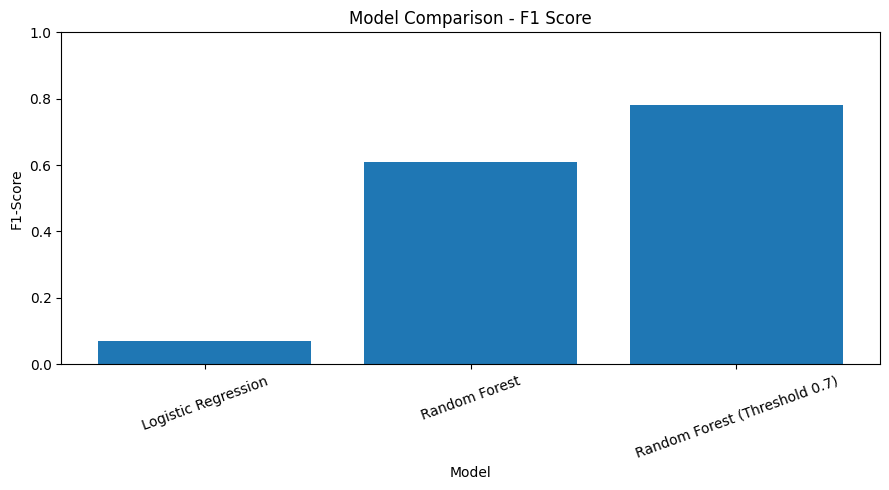

In [64]:
# Visual comparison of F1-Scores

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    results_df.index,
    results_df["F1-Score"]
)

plt.title("Model Comparison - F1 Score")
plt.xlabel("Model")
plt.ylabel("F1-Score")
plt.xticks(rotation=20)
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

In [65]:
# Find Random Forest related variables currently available

print([
    name for name in globals()
    if "rf" in name.lower() or "forest" in name.lower()
])

['RandomForestClassifier', 'random_forest_model', 'rf_val_pred', 'rf_val_proba', 'rf_cm', 'rf_accuracy', 'rf_precision', 'rf_recall', 'rf_f1', 'rf_roc_auc', 'rf_threshold_results', 'rf_threshold_pred', 'rf_threshold_df', 'best_rf_threshold_row', 'best_rf_threshold', 'y_val_rf_best_pred', 'rf_final_accuracy', 'rf_final_precision', 'rf_final_recall', 'rf_final_f1']


In [66]:
# Final evaluation on the untouched test dataset

test_proba = random_forest_model.predict_proba(
    X_test_processed
)[:, 1]

y_test_pred = (
    test_proba >= best_rf_threshold
).astype(int)

print("Test predictions generated successfully!")
print("Selected threshold:", best_rf_threshold)
print("Number of test predictions:", len(y_test_pred))

Test predictions generated successfully!
Selected threshold: 0.7
Number of test predictions: 555719


In [67]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred, zero_division=0)
test_recall = recall_score(y_test, y_test_pred, zero_division=0)
test_f1 = f1_score(y_test, y_test_pred, zero_division=0)
test_roc_auc = roc_auc_score(y_test, test_proba)

print("FINAL TEST SET PERFORMANCE")
print("--------------------------")
print(f"Accuracy  : {test_accuracy:.4f}")
print(f"Precision : {test_precision:.4f}")
print(f"Recall    : {test_recall:.4f}")
print(f"F1-Score  : {test_f1:.4f}")
print(f"ROC-AUC   : {test_roc_auc:.4f}")

FINAL TEST SET PERFORMANCE
--------------------------
Accuracy  : 0.9979
Precision : 0.7384
Recall    : 0.6909
F1-Score  : 0.7139
ROC-AUC   : 0.9897


In [68]:
from sklearn.metrics import confusion_matrix

test_cm = confusion_matrix(y_test, y_test_pred)

print("FINAL TEST CONFUSION MATRIX")
print(test_cm)

FINAL TEST CONFUSION MATRIX
[[553049    525]
 [   663   1482]]


In [69]:
import joblib

joblib.dump(random_forest_model, "random_forest_model.pkl")

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [70]:
print("Total features:", len(feature_names))
print("First 10 features:")
print(feature_names[:10])

Total features: 79
First 10 features:
['num__amt' 'num__lat' 'num__long' 'num__city_pop' 'num__merch_lat'
 'num__merch_long' 'num__transaction_hour' 'num__transaction_day'
 'num__transaction_month' 'num__transaction_dayofweek']


In [71]:
joblib.dump(feature_names, "feature_names.pkl")

print("Feature names saved successfully!")
print("Total features:", len(feature_names))

Feature names saved successfully!
Total features: 79


In [72]:
import os

print("random_forest_model.pkl:", os.path.exists("random_forest_model.pkl"))
print("feature_names.pkl:", os.path.exists("feature_names.pkl"))

random_forest_model.pkl: True
feature_names.pkl: True


In [73]:
print([
    name for name in globals()
    if any(x in name.lower() for x in ["encoder", "scaler", "transformer", "preprocess"])
])

['StandardScaler', 'ColumnTransformer', 'OneHotEncoder', 'preprocessor']


In [74]:
import joblib

joblib.dump(preprocessor, "preprocessor.pkl")

print("Preprocessor saved successfully!")

Preprocessor saved successfully!


In [75]:
joblib.dump(best_rf_threshold, "best_threshold.pkl")

print("Best threshold saved successfully!")
print("Threshold:", best_rf_threshold)

Best threshold saved successfully!
Threshold: 0.7


In [76]:
import os

files_to_check = [
    "random_forest_model.pkl",
    "feature_names.pkl",
    "preprocessor.pkl",
    "best_threshold.pkl"
]

for file in files_to_check:
    print(file, "->", "Saved" if os.path.exists(file) else "Missing")

random_forest_model.pkl -> Saved
feature_names.pkl -> Saved
preprocessor.pkl -> Saved
best_threshold.pkl -> Saved


In [77]:
import joblib

loaded_model = joblib.load("random_forest_model.pkl")
loaded_preprocessor = joblib.load("preprocessor.pkl")
loaded_features = joblib.load("feature_names.pkl")
loaded_threshold = joblib.load("best_threshold.pkl")

print("All files loaded successfully!")
print("Number of features:", len(loaded_features))
print("Threshold:", loaded_threshold)

All files loaded successfully!
Number of features: 79
Threshold: 0.7


In [78]:
print("Model type:", type(loaded_model).__name__)
print("Preprocessor type:", type(loaded_preprocessor).__name__)

Model type: RandomForestClassifier
Preprocessor type: ColumnTransformer


In [79]:
import pandas as pd

sample_customer = pd.DataFrame({
    "amt": [100.0],
    "lat": [40.7128],
    "long": [-74.0060],
    "city_pop": [50000],
    "merch_lat": [40.7306],
    "merch_long": [-73.9352],
    "transaction_hour": [14],
    "transaction_day": [15],
    "transaction_month": [6],
    "transaction_dayofweek": [2],
    "age": [35],
    "distance_km": [5.5],
    "gender": ["M"],
    "category": ["grocery_pos"],
    "state": ["NY"]
})

print(sample_customer)

     amt      lat    long  city_pop  merch_lat  merch_long  transaction_hour  \
0  100.0  40.7128 -74.006     50000    40.7306    -73.9352                14   

   transaction_day  transaction_month  transaction_dayofweek  age  \
0               15                  6                      2   35   

   distance_km gender     category state  
0          5.5      M  grocery_pos    NY  


In [80]:
# Transform the new customer using the saved preprocessor
sample_processed = loaded_preprocessor.transform(sample_customer)

print("Customer data preprocessed successfully!")
print("Processed shape:", sample_processed.shape)

Customer data preprocessed successfully!
Processed shape: (1, 79)


In [82]:
# Predict fraud probability
fraud_probability = loaded_model.predict_proba(sample_processed)[0, 1]

# Apply the saved threshold
prediction = int(fraud_probability >= loaded_threshold)

print("Fraud Probability:", round(fraud_probability * 100, 2), "%")

if prediction == 1:
    print("Final Prediction: FRAUD")
else:
    print("Final Prediction: LEGITIMATE")

Fraud Probability: 9.44 %
Final Prediction: LEGITIMATE


In [83]:
import os

files_to_check = [
    "app.py",
    "random_forest_model.pkl",
    "preprocessor.pkl",
    "feature_names.pkl",
    "best_threshold.pkl"
]

for file in files_to_check:
    print(file, "->", "Found" if os.path.exists(file) else "Missing")

app.py -> Found
random_forest_model.pkl -> Found
preprocessor.pkl -> Found
feature_names.pkl -> Found
best_threshold.pkl -> Found


In [84]:
import subprocess
import sys

process = subprocess.Popen([
    sys.executable, "-m", "streamlit",
    "run", "app.py"
])

print("Streamlit launch command started.")

Streamlit launch command started.
